# Can LoFTR find more real matches? (input size and coarse threshold)

The fine stage needs inliers: the new map gives LoFTR about half the inliers of the old one, and many right places end with too few to be answered. Lowering the answer bar to 3 is **not** the fix (a bar that low depends on luck); the fix is to make the matcher see more **real** matches.

Two things limit LoFTR here:

* **Input size.** The canvas and the map window are 224 x 224 px, and LoFTR matches on a coarse grid of 1/8 of the size: 28 x 28 = 784 cells at most. Enlarging both pictures before LoFTR (`upscale`) gives a finer grid (2.0 gives 56 x 56); the matches are mapped back to the 224 px frame, so everything after the matcher is unchanged.
* **Coarse threshold.** LoFTR keeps a coarse match only when its probability is above 0.2. A lower value lets weaker matches through.

More matches is only good if they are **real** ones. So every variant is measured twice: on the **right** places (inliers should rise) and on **wrong** places, the best-ranked wrong coarse peaks (inliers should stay low; if they rise too, the matcher just got noisier and the answer bar cannot use them). The numbers that decide: how often the pipeline's own rule (take the candidate with the most inliers, answer if it reaches the bar) answers **right** and how often it answers **wrong**, and the points that make per photo (about +9 for a right answer, -20 for a wrong one). "Clean" (best right reaches the bar and every wrong one stays under it) is a stricter reading and is also shown.

Nothing in the pipeline is changed by this notebook. The photos are spread over the whole set (not only the first 100 used by `Stage_Evaluation`).

**Result of the first run (kept in `LoFTR_Upscale_Check_executed.ipynb`): enlarging the inputs does not help.** At threshold 0.2 the matches per pair fall from 8 (size 1.0) to 4 (1.5), 2 (2.0) and 0 (3.0), the inliers on right places fall with them, and each step is slower. `UPSCALE_LIST` is therefore `[1.0]` here; the option stays in `src` (default 1.0) for anyone who wants to try another matcher on it.

**Photos with no right place.** When the coarse stage never reaches the right place, every answer is wrong, and a matcher that finds more inliers on wrong places turns a harmless skip (0) into a -20. These photos are kept in the count (their candidates are all wrong), so the points per photo are for **all** checked photos.

In [1]:
import os, sys, math, time, gc
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2, torch
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "single_photo_pipeline.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "src")); os.chdir(ROOT)

# ------------------------------------------------------------------ settings
MAP = "new"                 # base map of the official photos (see src/header/map_source.py)
MAP_MARGIN_M = 2500         # metres of map around the photos: smaller than the pipeline default, to set up faster
N_PHOTOS = 500
N_CHECK = 200               # photos checked (spread over the whole set)
K_PEAKS = 25                # coarse peaks looked at per photo
N_WRONG = 24                # the best-ranked WRONG peaks that are matched per photo (look-alike places, the dangerous ones)
UPSCALE_LIST = [1.0]             # 1.5, 2.0 and 3.0 were measured in the first run and are worse
THR_LIST = [0.2, 0.1, 0.05]
CONF_TIGHT = 0.3            # the pipeline's confidence cut; "loose" keeps every match LoFTR proposes at the threshold
RANSAC_PIXELS = 3.0
BARS = [8, 12]              # answer bars the result is read at (the pipeline uses 12; Stage_Evaluation 8)
FOUND_SIGMA = 4.0
SEED = 45
plt.rcParams["figure.dpi"] = 90

## 1 · Set up the pipeline pieces (coarse search only) and pick the candidates

In [2]:
from single_photo_pipeline import SinglePhotoPipeline
from header import settings
from image_processing.geometry import render_query
from image_processing.map_levels import level_for_height, map_piece
from train.coarse_methods.inputs import make_inputs
from semantic_rerank.dino_rerank import coarse_top
from fine_matching.loftr_matcher import loftr_matches, fit_matches, prepare_roma_canvas
from header.settings import CTX

pipeline = SinglePhotoPipeline("official", "fused", semantic_layer=False, k_peaks=K_PEAKS, m_fine=K_PEAKS, matcher="loftr_minima",
                               satellite=MAP, map_margin_m=MAP_MARGIN_M)
start = time.time()
pipeline.setup(N_PHOTOS, SEED)
print("setup %.0f s" % (time.time() - start))
test_set, camera, level_images, matcher = pipeline.test_set, pipeline.camera, pipeline.level_images, pipeline.matcher

order = np.linspace(0, len(test_set.items) - 1, N_CHECK).astype(int)
cases = []                       # one entry per photo: the picture, and the right and wrong candidates (position, role)
skipped = 0
for index in order:
    item = test_set.items[index]
    truth, sigma = test_set.truths[index], test_set.sigmas[index]
    level = level_for_height(item["rel_height"], camera)
    canvas, valid = render_query(item, camera, level)
    cv2.setRNGSeed(settings.SEED)
    inputs = make_inputs(canvas, valid, level, test_set.priors[index], pipeline.families, pipeline.names)
    peaks = coarse_top(pipeline.coarse_method(inputs), inputs["geometry"], K_PEAKS)
    del inputs
    errors = np.array([math.hypot(p[1] - truth[0], p[2] - truth[1]) / sigma if p[1] < 1e8 else 1e9 for p in peaks])
    right = [k for k in range(len(peaks)) if errors[k] <= FOUND_SIGMA]
    wrong = [k for k in range(len(peaks)) if errors[k] > FOUND_SIGMA and peaks[k, 1] < 1e8][:N_WRONG]
    if len(right) == 0:
        skipped += 1                                         # kept: every candidate is wrong, an answer here costs -20
    right = right[:3]
    picture, reliable = prepare_roma_canvas(canvas, valid)
    cases.append(dict(has_right=len(right) > 0, photo=int(index), height=item["rel_height"], level=level, sigma=sigma, truth=truth, picture=picture, reliable=reliable,
                      candidates=[dict(x=peaks[k, 1], y=peaks[k, 2], role="right", rank=k) for k in right] + [dict(x=peaks[k, 1], y=peaks[k, 2], role="wrong", rank=k) for k in wrong]))
    torch.cuda.empty_cache()
print("%d photos checked: %d have a right place among the first %d coarse peaks, %d have none (lost before the fine stage; their candidates are all wrong)" % (len(cases), len(cases) - skipped, K_PEAKS, skipped))
print("candidates per photo: %.1f right + %.1f wrong" % (np.mean([sum(c["role"] == "right" for c in case["candidates"]) for case in cases if case["has_right"]]), np.mean([sum(c["role"] == "wrong" for c in case["candidates"]) for case in cases])))

level 3: 0.85 m/pixel, picture 8035 x 7710, map coverage 100%
level 4: 1.20 m/pixel, picture 5682 x 5452, map coverage 100%
level 5: 1.70 m/pixel, picture 4017 x 3855, map coverage 100%
level 6: 2.40 m/pixel, picture 2841 x 2726, map coverage 100%
level 7: 3.39 m/pixel, picture 2008 x 1927, map coverage 100%


map store ready, took 22 s


/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/kornia/feature/lightglue.py:44: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)


setup 38 s


200 photos checked: 177 have a right place among the first 25 coarse peaks, 23 have none (lost before the fine stage; their candidates are all wrong)
candidates per photo: 1.0 right + 24.0 wrong


## 2 · Run LoFTR on every candidate, once per variant (input size x coarse threshold)

The raw matches (positions and confidence) are kept, so the confidence cut and the RANSAC distance can be changed afterwards without running the network again.

In [3]:
raw = {}
seconds = {}
model = matcher.loftr_model
base_thr = model.coarse_matching.thr
for upscale in UPSCALE_LIST:
    for thr in THR_LIST:
        matcher.upscale = upscale
        model.coarse_matching.thr = thr
        stored = {}
        start = time.time()
        pairs = 0
        for case in cases:
            for position, cand in enumerate(case["candidates"]):
                tile = map_piece(level_images, case["level"], cand["x"], cand["y"], CTX)
                stored[(case["photo"], position)] = loftr_matches(matcher, case["picture"], tile)
                pairs += 1
        if settings.DEVICE == "cuda":
            torch.cuda.synchronize()
        raw[(upscale, thr)] = stored
        seconds[(upscale, thr)] = (time.time() - start) / pairs
        print("upscale %.1f, threshold %.2f: %d pairs, %.3f s per pair, %.0f matches per pair" % (
            upscale, thr, pairs, seconds[(upscale, thr)], np.mean([len(v[2]) for v in stored.values()])))
matcher.upscale = 1.0
model.coarse_matching.thr = base_thr

upscale 1.0, threshold 0.20: 4972 pairs, 0.040 s per pair, 4 matches per pair


upscale 1.0, threshold 0.10: 4972 pairs, 0.060 s per pair, 10 matches per pair


upscale 1.0, threshold 0.05: 4972 pairs, 0.080 s per pair, 23 matches per pair


## 3 · Read every variant

For each variant and confidence cut (tight = 0.3, loose = keep everything above the threshold):

* **right: median inliers** and the share of photos whose best right candidate reaches the bar;
* **wrong: best inliers** (median and 95th percentile over photos) and the share of photos where a wrong candidate reaches the bar: a **false alarm**;
* **clean at bar**: best right reaches the bar and the best wrong stays under it. This is what the answer rule can use;
* **error after the shift** of the best right candidate, in sigma (the precision the matcher gives).

In [4]:
def fit_all(variant, conf_cut, px):
    """For one variant: inliers and corrected position error for every candidate, from the stored matches."""
    out = {}
    for case in cases:
        for position, cand in enumerate(case["candidates"]):
            pa, pb, conf = raw[variant][(case["photo"], position)]
            cv2.setRNGSeed(settings.SEED)
            result = fit_matches(pa, pb, conf, case["reliable"], case["level"], conf_cut, px)
            error_sigma = math.hypot(cand["x"] + result["shift"][0] - case["truth"][0], cand["y"] + result["shift"][1] - case["truth"][1]) / case["sigma"]
            out[(case["photo"], position)] = (result["n_inliers"], error_sigma)
    return out


def read_variant(variant, conf_cut, px=RANSAC_PIXELS):
    fits = fit_all(variant, conf_cut, px)
    best_right, best_wrong, error_of_best, has_right = [], [], [], []
    for case in cases:
        right = [(fits[(case["photo"], k)][0], fits[(case["photo"], k)][1]) for k, c in enumerate(case["candidates"]) if c["role"] == "right"]
        wrong = [fits[(case["photo"], k)][0] for k, c in enumerate(case["candidates"]) if c["role"] == "wrong"]
        has_right.append(len(right) > 0)
        if right:
            top = max(right, key=lambda r: r[0])
            best_right.append(top[0]); error_of_best.append(top[1])
        else:
            best_right.append(-1); error_of_best.append(np.nan)                  # no right place among the candidates: nothing can be answered right
        best_wrong.append(max(wrong) if wrong else 0)
    best_right, best_wrong, error_of_best, has_right = np.array(best_right), np.array(best_wrong), np.array(error_of_best), np.array(has_right)
    row = {"upscale": variant[0], "threshold": variant[1], "confidence cut": conf_cut, "s per pair": seconds[variant],
           "right: median inliers": np.median(best_right[has_right]), "right: 25th pct": np.percentile(best_right[has_right], 25),
           "wrong: median best": np.median(best_wrong), "wrong: 95th pct": np.percentile(best_wrong, 95),
           "median error after shift (sigma)": np.nanmedian(error_of_best[has_right & (best_right >= 8)]) if (has_right & (best_right >= 8)).any() else np.nan}
    for bar in BARS:
        row["right >= %d" % bar] = (best_right[has_right] >= bar).mean()
        row["false alarm at %d" % bar] = (best_wrong >= bar).mean()
        # what the pipeline does: it takes the candidate with the most inliers, and answers if that count reaches the bar
        answered_right = has_right & (best_right >= bar) & (best_right > best_wrong)
        answered_wrong = (best_wrong >= bar) & (best_wrong >= best_right)
        row["answered right at %d" % bar] = answered_right.mean()
        row["answered WRONG at %d" % bar] = answered_wrong.mean()
        row["... of which on photos with no right place"] = (answered_wrong & ~has_right).sum() / max((~has_right).sum(), 1) if bar == BARS[0] else row.get("... of which on photos with no right place")
        row["points at %d" % bar] = 9.0 * answered_right.mean() - 20.0 * answered_wrong.mean()      # about +9 for a right answer, -20 for a wrong one, per checked photo
    return row


rows = []
for variant in raw:
    rows.append(read_variant(variant, CONF_TIGHT))
    if variant[1] != CONF_TIGHT:
        rows.append(read_variant(variant, variant[1]))                  # loose: every match LoFTR proposes at this threshold
table = pd.DataFrame(rows).drop_duplicates(subset=["upscale", "threshold", "confidence cut"])
print("%d photos (%d with a right place), %d candidates | baseline = threshold 0.2, confidence cut %.1f (what the pipeline does today)" % (
    len(cases), sum(c["has_right"] for c in cases), sum(len(c["candidates"]) for c in cases), CONF_TIGHT))
display(table.sort_values("points at %d" % BARS[-1], ascending=False).round(3).reset_index(drop=True))


200 photos (177 with a right place), 4972 candidates | baseline = threshold 0.2, confidence cut 0.3 (what the pipeline does today)


,upscale,threshold,confidence cut,s per pair,right: median inliers,right: 25th pct,wrong: median best,wrong: 95th pct,median error after shift (sigma),right >= 8,false alarm at 8,answered right at 8,answered WRONG at 8,... of which on photos with no right place,points at 8,right >= 12,false alarm at 12,answered right at 12,answered WRONG at 12,points at 12
0,1.0,0.05,0.05,0.08,62.0,32.0,7.0,12.05,0.588,0.983,0.360,0.865,0.040,0.304,6.985,0.972,0.065,0.860,0.010,7.540
1,1.0,0.10,0.10,0.06,51.0,23.0,5.0,9.05,0.574,0.955,0.100,0.845,0.015,0.130,7.305,0.904,0.025,0.800,0.005,7.100
2,1.0,0.20,0.20,0.04,30.0,12.0,3.0,6.00,0.597,0.853,0.020,0.755,0.005,0.043,6.695,0.751,0.000,0.665,0.000,5.985
3,1.0,0.20,0.30,0.04,20.0,7.0,0.0,4.00,0.609,0.740,0.005,0.655,0.000,0.000,5.895,0.678,0.000,0.600,0.000,5.400
4,1.0,0.10,0.30,0.06,20.0,7.0,0.0,4.00,0.609,0.740,0.005,0.655,0.000,0.000,5.895,0.678,0.000,0.600,0.000,5.400
5,1.0,0.05,0.30,0.08,20.0,7.0,0.0,4.00,0.609,0.740,0.005,0.655,0.000,0.000,5.895,0.678,0.000,0.600,0.000,5.400


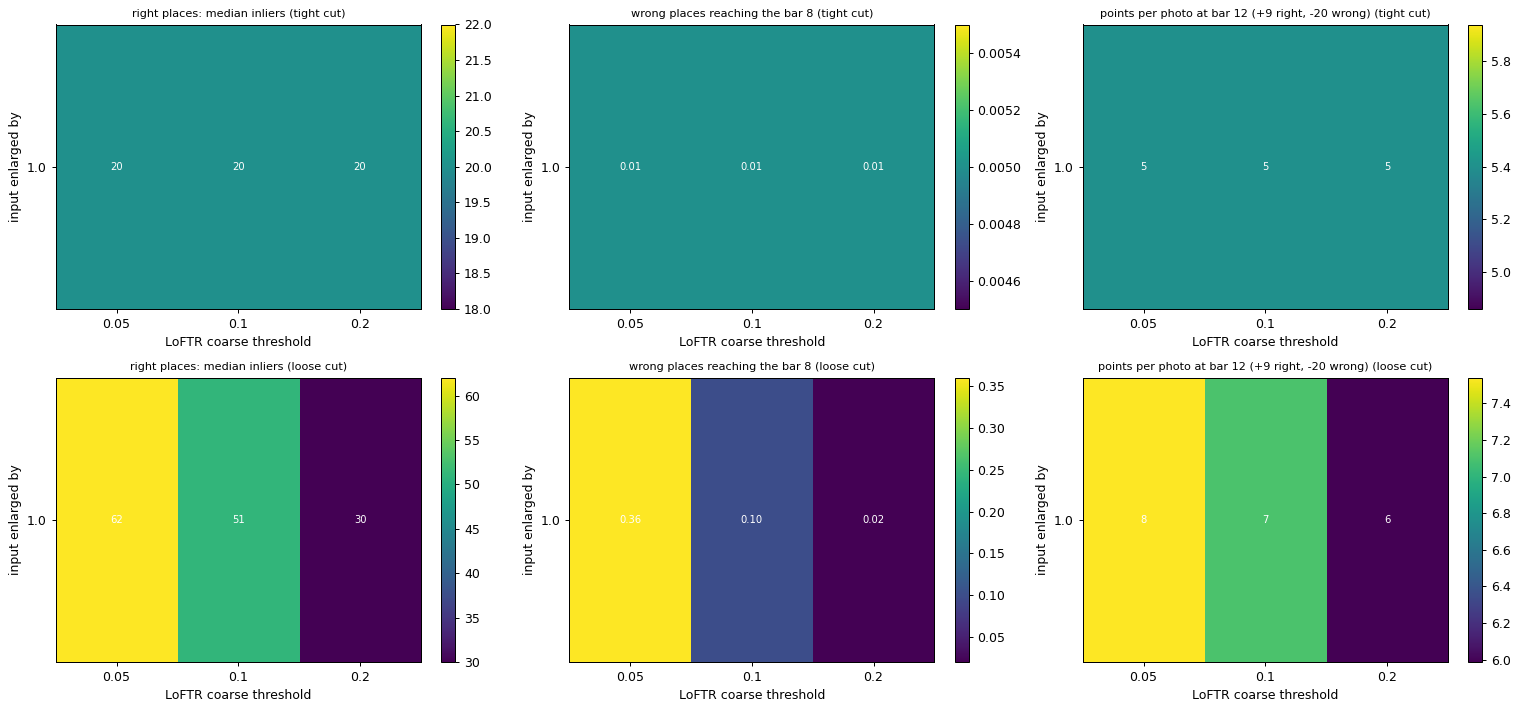

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for r, cut_name in enumerate(("tight", "loose")):
    part = table[(table["confidence cut"] == CONF_TIGHT)] if cut_name == "tight" else table[(table["confidence cut"] == table["threshold"]) & (table["threshold"] != CONF_TIGHT)]
    for axis, column, title in ((axes[r, 0], "right: median inliers", "right places: median inliers"), (axes[r, 1], "false alarm at %d" % BARS[0], "wrong places reaching the bar %d" % BARS[0]),
                                (axes[r, 2], "points at %d" % BARS[-1], "points per photo at bar %d (+9 right, -20 wrong)" % BARS[-1])):
        grid = part.pivot_table(index="upscale", columns="threshold", values=column)
        image = axis.imshow(grid.values, cmap="viridis", aspect="auto")
        axis.set_xticks(range(len(grid.columns))); axis.set_xticklabels(grid.columns)
        axis.set_yticks(range(len(grid.index))); axis.set_yticklabels(grid.index)
        axis.set_xlabel("LoFTR coarse threshold"); axis.set_ylabel("input enlarged by")
        axis.set_title("%s (%s cut)" % (title, cut_name), fontsize=9)
        for i in range(grid.shape[0]):
            for j in range(grid.shape[1]):
                axis.text(j, i, "%.2f" % grid.values[i, j] if grid.values[i, j] < 5 else "%.0f" % grid.values[i, j], ha="center", va="center", color="white", fontsize=8)
        plt.colorbar(image, ax=axis, fraction=0.046)
plt.tight_layout()
plt.show()

## 4 · The best variant against the baseline: inliers of right and of wrong places

best variant by points per photo at bar 12: upscale 1.0, threshold 0.05, confidence cut 0.05


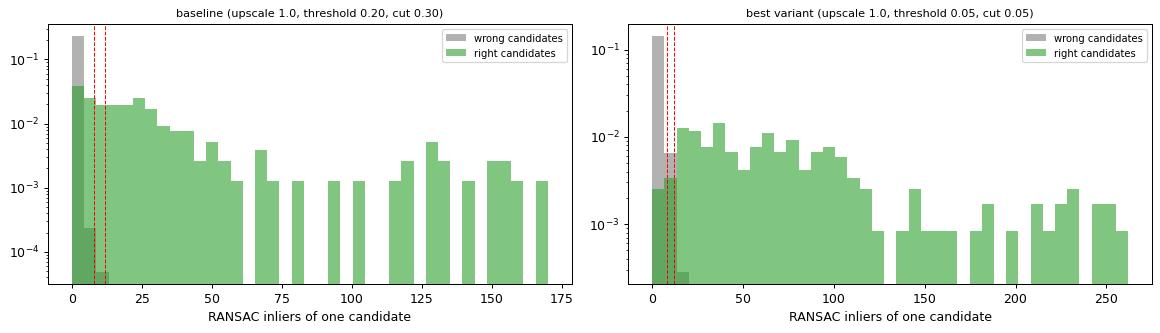

In [6]:
pick = table.sort_values(["points at %d" % BARS[-1], "answered WRONG at %d" % BARS[-1]], ascending=[False, True]).iloc[0]
best_variant = (pick["upscale"], pick["threshold"])
best_cut = pick["confidence cut"]
print("best variant by points per photo at bar %d: upscale %.1f, threshold %.2f, confidence cut %.2f" % (BARS[-1], best_variant[0], best_variant[1], best_cut))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for axis, (variant, cut, name) in zip(axes, [((1.0, 0.2), CONF_TIGHT, "baseline"), (best_variant, best_cut, "best variant")]):
    fits = fit_all(variant, cut, RANSAC_PIXELS)
    right_values = [fits[(c["photo"], k)][0] for c in cases for k, cand in enumerate(c["candidates"]) if cand["role"] == "right"]
    wrong_values = [fits[(c["photo"], k)][0] for c in cases for k, cand in enumerate(c["candidates"]) if cand["role"] == "wrong"]
    top = max(right_values + wrong_values + [10])
    bins = np.linspace(0, top, 40)
    axis.hist(wrong_values, bins=bins, alpha=0.6, color="tab:gray", label="wrong candidates", density=True)
    axis.hist(right_values, bins=bins, alpha=0.6, color="tab:green", label="right candidates", density=True)
    for bar in BARS:
        axis.axvline(bar, color="red", ls="--", lw=0.8)
    axis.set_yscale("log"); axis.set_xlabel("RANSAC inliers of one candidate"); axis.legend(fontsize=8)
    axis.set_title("%s (upscale %.1f, threshold %.2f, cut %.2f)" % (name, variant[0], variant[1], cut), fontsize=9)
plt.tight_layout()
plt.show()

## 5 · On the best variant: the confidence cut and the RANSAC distance (from the stored matches)

In [7]:
rows = []
for cut in sorted(set([best_variant[1], 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6])):
    if cut < best_variant[1]:
        continue
    for px in (1.5, 2.0, 3.0, 4.0, 6.0):
        row = read_variant(best_variant, cut, px)
        row["ransac px"] = px
        rows.append(row)
sweep = pd.DataFrame(rows)
print("best variant (upscale %.1f, threshold %.2f): confidence cut x RANSAC distance, read at bar %d" % (best_variant[0], best_variant[1], BARS[0]))
for bar in BARS:
    print("points per photo at bar %d (about +9 right, -20 wrong):" % bar)
    display(sweep.pivot_table(index="confidence cut", columns="ransac px", values="points at %d" % bar).round(2))
    print("share of photos answered WRONG at bar %d:" % bar)
    display(sweep.pivot_table(index="confidence cut", columns="ransac px", values="answered WRONG at %d" % bar).round(3))
out_dir = ROOT / "tests" / "Test_Iteration_2" / "results" / "loftr_more_matches"
out_dir.mkdir(parents=True, exist_ok=True)
table.to_csv(out_dir / "variants.csv", index=False)
sweep.to_csv(out_dir / "best_variant_conf_ransac.csv", index=False)
print("saved in", out_dir)

best variant (upscale 1.0, threshold 0.05): confidence cut x RANSAC distance, read at bar 8
points per photo at bar 8 (about +9 right, -20 wrong):


ransac px,1.5,2.0,3.0,4.0,6.0
confidence cut,,,,,
0.05,7.44,7.14,6.98,6.84,6.73
0.10,7.24,6.98,7.30,7.15,7.20
0.15,6.75,6.83,7.01,7.06,7.10
0.20,6.26,6.44,6.70,6.74,6.83
0.25,5.80,6.03,6.26,6.48,6.62
0.30,5.54,5.72,5.90,6.03,6.08
0.40,4.36,4.86,5.22,5.31,5.31
0.50,3.15,3.87,4.14,4.19,4.27
0.60,2.11,2.34,2.79,2.88,2.92


share of photos answered WRONG at bar 8:


ransac px,1.5,2.0,3.0,4.0,6.0
confidence cut,,,,,
0.05,0.015,0.030,0.040,0.045,0.055
0.10,0.005,0.020,0.015,0.025,0.025
0.15,0.000,0.005,0.005,0.005,0.005
0.20,0.000,0.000,0.005,0.005,0.005
0.25,0.000,0.000,0.000,0.000,0.000
0.30,0.000,0.000,0.000,0.000,0.000
0.40,0.000,0.000,0.000,0.000,0.000
0.50,0.000,0.000,0.000,0.000,0.000
0.60,0.000,0.000,0.000,0.000,0.000


points per photo at bar 12 (about +9 right, -20 wrong):


ransac px,1.5,2.0,3.0,4.0,6.0
confidence cut,,,,,
0.05,7.20,7.50,7.54,7.44,7.38
0.10,6.48,6.84,7.10,7.14,7.24
0.15,5.98,6.12,6.66,6.88,6.88
0.20,5.54,5.80,5.98,6.26,6.44
0.25,5.44,5.58,5.62,5.85,5.94
0.30,4.54,5.04,5.40,5.49,5.49
0.40,3.24,3.60,4.14,4.54,4.64
0.50,2.11,2.39,2.70,2.84,2.97
0.60,1.48,1.66,1.71,1.71,1.80


share of photos answered WRONG at bar 12:


ransac px,1.5,2.0,3.0,4.0,6.0
confidence cut,,,,,
0.05,0.0,0.005,0.010,0.015,0.020
0.10,0.0,0.000,0.005,0.005,0.005
0.15,0.0,0.000,0.000,0.000,0.005
0.20,0.0,0.000,0.000,0.000,0.000
0.25,0.0,0.000,0.000,0.000,0.000
0.30,0.0,0.000,0.000,0.000,0.000
0.40,0.0,0.000,0.000,0.000,0.000
0.50,0.0,0.000,0.000,0.000,0.000
0.60,0.0,0.000,0.000,0.000,0.000


saved in /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Test_Iteration_2/results/loftr_more_matches


## Verdict (200 photos, 177 with a right place, 23 lost before the fine stage, 24 wrong candidates per photo)

* **Enlarging the input does not help** (first run, `LoFTR_Upscale_Check_executed.ipynb`): fewer matches and fewer inliers, slower.
* **The confidence cut is what costs matches.** Today's setting (LoFTR threshold 0.2, confidence cut 0.3) leaves the best right candidate with a median of 20 inliers. With both at 0.1 it is 51, with both at 0.05 it is 62.
* **Answered right / wrong with the pipeline's own rule (most inliers wins), at bar 12:** today 60 % / 0 %; threshold and cut 0.1: 80 % / 0.5 % (1 photo of 200); 0.05: 86 % / 1 %. At bar 8: 66 % / 0 %, 84 % / 1.5 %, 86 % / 4 %.
* **Points per photo** (about +9 right, -20 wrong): bar 12: 5.4, 7.1, 7.5; bar 8: 5.9, 7.3, 7.0. The step from today's setting to 0.1 is large and safe; the step from 0.1 to 0.05 adds little and brings more wrong answers (at bar 8 it loses points).
* **Photos the coarse stage lost** (nobody can answer them right): with 0.1 a wrong answer appears on 13 % of them at bar 8 and about 2.5 % at bar 12; with 0.05 on 30 % at bar 8. This is the price, and it is why the bar should stay at 12 (or 8 at the lowest), not be lowered.
* **Chosen:** LoFTR coarse threshold 0.1 and confidence cut 0.1, RANSAC distance unchanged (3 px), answer bar unchanged. `Single_Image_Run.ipynb` and `Stage_Evaluation.ipynb` now use these values; `src` and `single_photo_pipeline.py` keep the old values as their defaults (the parameters `loftr_coarse_threshold` and `matcher_confidence`).

Caveats: the photos here are the official d1 photos on the new map (one place, one sensor); the wrong candidates are the best-ranked wrong coarse peaks of each photo; the points are an estimate (+9 for a right answer), not the contest score. Re-check on a different set of photos before relying on the gap between 0.1 and 0.05.